### Build the Wrangle Function

In [15]:
%pip install duckdb
import duckdb 
import pandas as pd
!pip install category_encoders

Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 7.5 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.5.1
    Uninstalling scikit-learn-1.5.1:
      Successfully uninstalled scikit-learn-1.5.1


In [4]:
def wrangle_nepal_data(csv_path="./data", district_id=None):
    """
    Retrieve and prepare Nepal earthquake data for binary classification.

    This function reads CSV files using DuckDB and joins building structure
    with building damage data. The damage_grade column is kept as-is for use
    in creating the target variable in Lesson 2.

    Parameters:
    -----------
    csv_path : str
        Path to the data folder (default: "./data")
    district_id : int, optional
        Filter by specific district (e.g., 4 for Gorkha).
        If None, returns all districts.

    Returns:
    --------
    pd.DataFrame
        DataFrame with features and damage_grade column
    """
    # Build file paths
    structure_path = f"{csv_path}/building_structure.csv"
    damage_path = f"{csv_path}/building_damage.csv"

    # Build WHERE clause
    where_clause = "WHERE b.damage_grade IS NOT NULL"
    if district_id is not None:
        where_clause += f" AND i.district_id = {district_id}"

    # Always join with id_map to get district_id
    query = f"""
        SELECT DISTINCT 
            s.building_id,
            i.district_id,
            s.age_building,
            s.plinth_area_sq_ft,
            s.height_ft_pre_eq,
            s.foundation_type,
            s.ground_floor_type,
            b.damage_grade
        FROM read_csv_auto('{structure_path}') s
        JOIN read_csv_auto('{damage_path}') b ON s.building_id = b.building_id
        JOIN read_csv_auto('./data/id_map.csv') i ON s.building_id = i.building_id
        {where_clause}
    """

    return (
        duckdb.sql(query)
        .df()
        .set_index("building_id")
        .assign(
            severe_damage=lambda x: (
                x["damage_grade"]
                .str.contains("Grade 4|Grade 5")
                .fillna(False)
                .astype(int)
            )
        )
        .drop(columns=["damage_grade"])
    )

# 1. Data Acquisition and Cleaning

In [315]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_curve, roc_auc_score
import warnings
warnings.filterwarnings("ignore")
# Set display options
pd.set_option('display.max_columns', None)

In [136]:
building_damage = pd.read_csv('/Users/otistran/Documents/WorldQuant/Project 4/building_damage.csv')
building_structure = pd.read_csv('/Users/otistran/Documents/WorldQuant/Project 4/building_structure.csv')
household_demographics = pd.read_csv('/Users/otistran/Documents/WorldQuant/Project 4/household_demographics.csv')
id_map = pd.read_csv('/Users/otistran/Documents/WorldQuant/Project 4/id_map.csv')

In [156]:
query = f"""
    SELECT DISTINCT 
        s.building_id,
        i.district_id,
        s.age_building,
        s.plinth_area_sq_ft,
        s.height_ft_pre_eq,
        s.foundation_type,
        s.ground_floor_type,
        b.damage_grade
    FROM building_structure s
    JOIN building_damage b ON s.building_id = b.building_id
    JOIN id_map i ON s.building_id = i.building_id
    WHERE b.damage_grade IS NOT NULL
    AND i.district_id = 4
    """

In [172]:
df = duckdb.sql(query).df()

In [168]:
def modify_severe_damage(data):
    df = (
        data.set_index("building_id")
        .assign(
            severe_damage = lambda x: (x["damage_grade"].str.contains("Grade 4|Grade 5")
                                                        .fillna(False)
                                                        .astype(int)
        )
        ).drop(columns = "damage_grade")
    )
    return df

In [174]:
df = modify_severe_damage(df)

In [176]:
df.shape

(70836, 7)

In [178]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 70836 entries, 204928 to 204791
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   district_id        70836 non-null  int64 
 1   age_building       70836 non-null  int64 
 2   plinth_area_sq_ft  70836 non-null  int64 
 3   height_ft_pre_eq   70836 non-null  int64 
 4   foundation_type    70836 non-null  object
 5   ground_floor_type  70836 non-null  object
 6   severe_damage      70836 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 4.3+ MB


In [182]:
df.describe()

,district_id,age_building,plinth_area_sq_ft,height_ft_pre_eq,severe_damage
count,70836.0,70836.000000,70836.000000,70836.000000,70836.000000
mean,4.0,25.759063,410.592961,15.068355,0.642597
std,0.0,61.214914,210.382540,4.750919,0.479238
min,4.0,0.000000,70.000000,6.000000,0.000000
25%,4.0,10.000000,265.000000,12.000000,0.000000
50%,4.0,19.000000,378.000000,14.000000,1.000000
75%,4.0,30.000000,504.000000,18.000000,1.000000
max,4.0,999.000000,4995.000000,99.000000,1.000000


In [192]:
nan_cols_pct = (df.isna().sum(axis = 0)*100/len(df)).sort_values()
nan_cols_pct

district_id          0.0
age_building         0.0
plinth_area_sq_ft    0.0
height_ft_pre_eq     0.0
foundation_type      0.0
ground_floor_type    0.0
severe_damage        0.0
dtype: float64

# 2. Exploratory Data Analysis

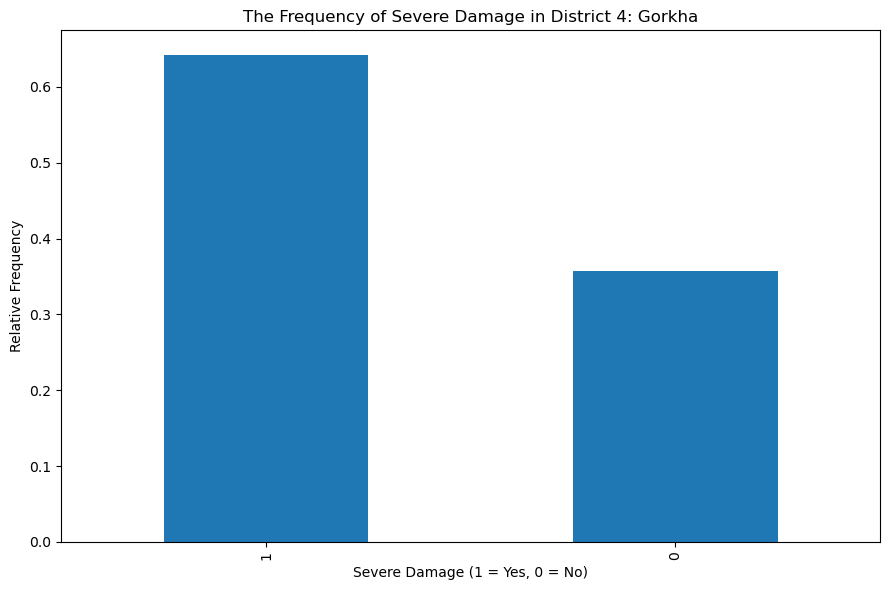

In [202]:
# Calculate class distribution
class_distribution = df["severe_damage"].value_counts(normalize = True)

fig, ax = plt.subplots(figsize = (9,6))
class_distribution.plot(kind = "bar", ax=ax)
ax.set_xlabel("Severe Damage (1 = Yes, 0 = No)")
ax.set_ylabel("Relative Frequency")
ax.set_title("The Frequency of Severe Damage in District 4: Gorkha")
plt.tight_layout()
plt.show()

In [208]:
cat_unique_counts = df.select_dtypes("object").nunique()

print(cat_unique_counts)

foundation_type      5
ground_floor_type    5
dtype: int64


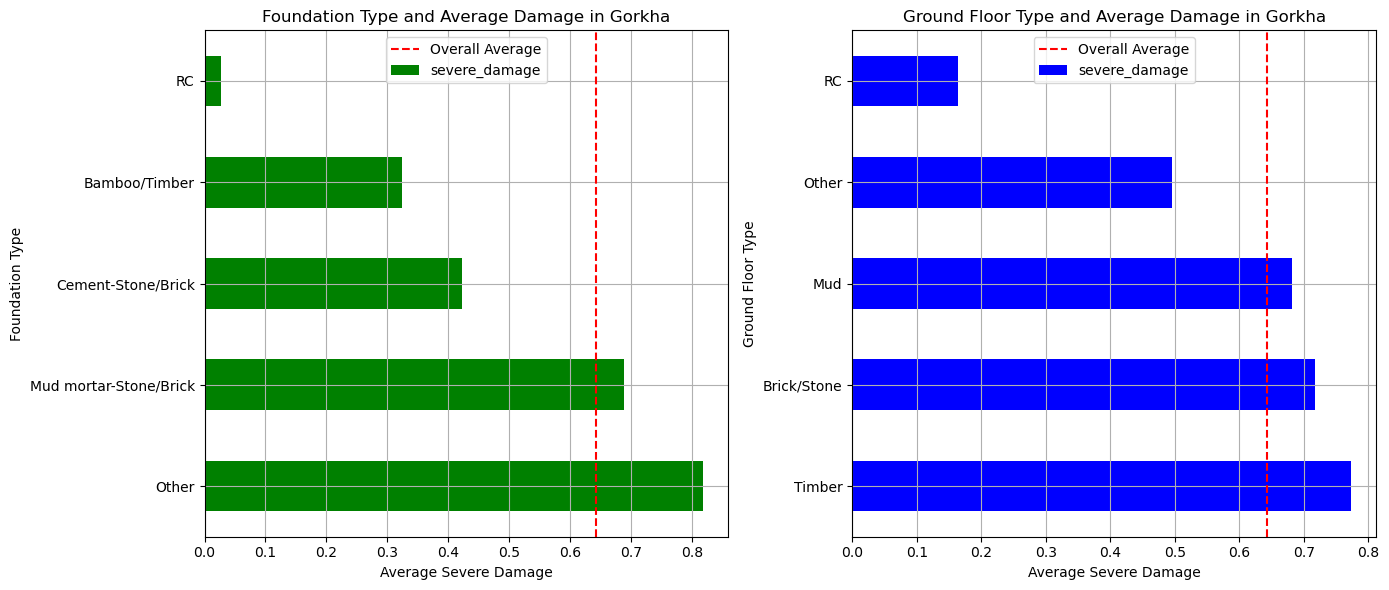

In [268]:
severe_damage_by_foundation = df.groupby("foundation_type")["severe_damage"].mean().sort_values(ascending=False)
severe_damage_by_ground_type = df.groupby("ground_floor_type")["severe_damage"].mean().sort_values(ascending=False)
fig, axes = plt.subplots(1,2,figsize = (14,6)) 
severe_damage_by_foundation.plot(kind = "barh",ax=axes[0], color = "green")
axes[0].axvline(x=df["severe_damage"].mean(), color="red", linestyle="--", label="Overall Average")
axes[0].set_xlabel("Average Severe Damage")
axes[0].set_ylabel("Foundation Type")
axes[0].set_title("Foundation Type and Average Damage in Gorkha")
axes[0].legend()
axes[0].grid()
severe_damage_by_ground_type.plot(kind = "barh", ax=axes[1], color = "blue")
axes[1].axvline(x=df["severe_damage"].mean(), linestyle="--",color="red",label="Overall Average")
axes[1].set_xlabel("Average Severe Damage")
axes[1].set_ylabel("Ground Floor Type")
axes[1].set_title("Ground Floor Type and Average Damage in Gorkha")
axes[1].legend()
plt.tight_layout()
plt.legend()
plt.grid()
plt.show()

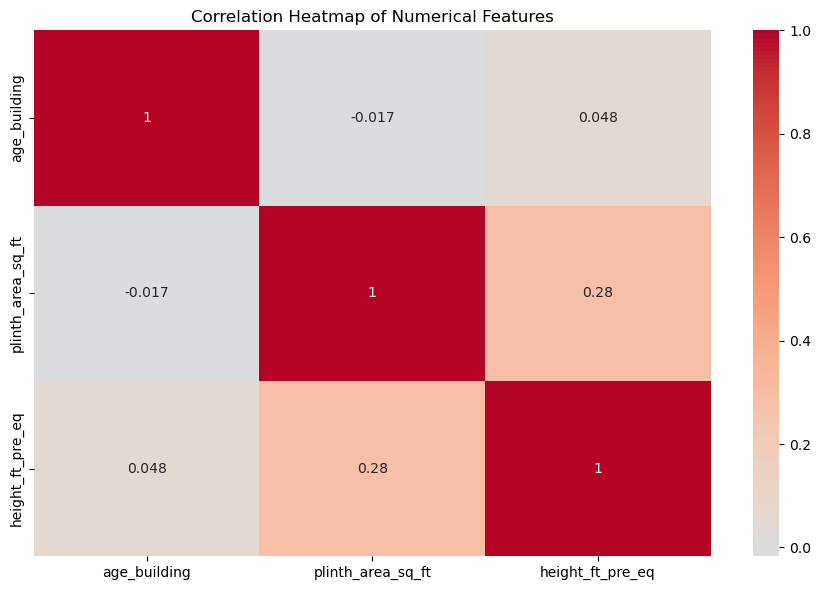

In [250]:
import seaborn as sns
correlation = df.select_dtypes("number").drop(columns = ["severe_damage","district_id"]).corr()

fig, ax = plt.subplots(figsize=(9,6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0,ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

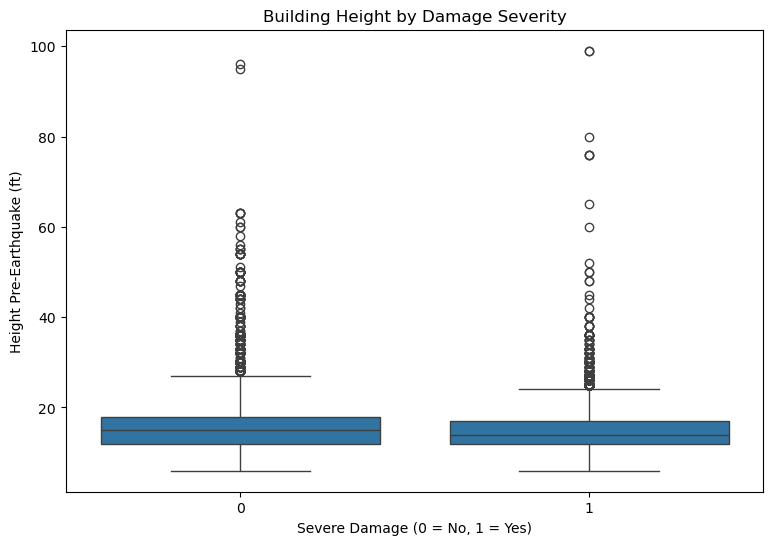

In [272]:
fig,ax = plt.subplots(figsize=(9,6))
sns.boxplot(x='severe_damage',y='height_ft_pre_eq',data=df,ax=ax)
ax.set_xlabel('Severe Damage (0 = No, 1 = Yes)')
ax.set_ylabel('Height Pre-Earthquake (ft)')
ax.set_title('Building Height by Damage Severity')
plt.show()

# 3. Machine Learning to Classify

### 3.1 Baseline Model: Linear Regression

In [281]:
# Define target and features
target = "severe_damage"

features = [col for col in df.columns if col != target]

In [285]:
# Train test split
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [289]:
# Baseline
baseline_acc = y_train.value_counts(normalize = True).max()
print(f"Baseline Accuracy: {baseline_acc}")

Baseline Accuracy: 0.6429378132279241


In [349]:
# Logistic Regression
from sklearn.pipeline import Pipeline
import category_encoders as ce
model_lr = Pipeline([
    ("encoder", ce.OneHotEncoder(use_cat_names=True)),
    ("classifier", LogisticRegression(max_iter=1000))
])
# Fit model
model_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoder', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['di...id', 'ag...ng', 'pl...ft', 'he...eq', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,cols,"['foundation_type', 'ground_floor_type']"
,use_cat_names,True
,verbose,0


In [351]:
# Evaluate 
train_acc = accuracy_score(y_train, model_lr.predict(X_train))
test_acc = accuracy_score(y_test, model_lr.predict(X_test))
print(train_acc)
print(test_acc)

0.7047187125008824
0.7033455674760023


In [353]:
# Calculate precision and recall
y_pred = model_lr.predict(X_test)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test, y_pred)
print(precision)
print(recall)

0.6927511054958939
0.9656576774903688


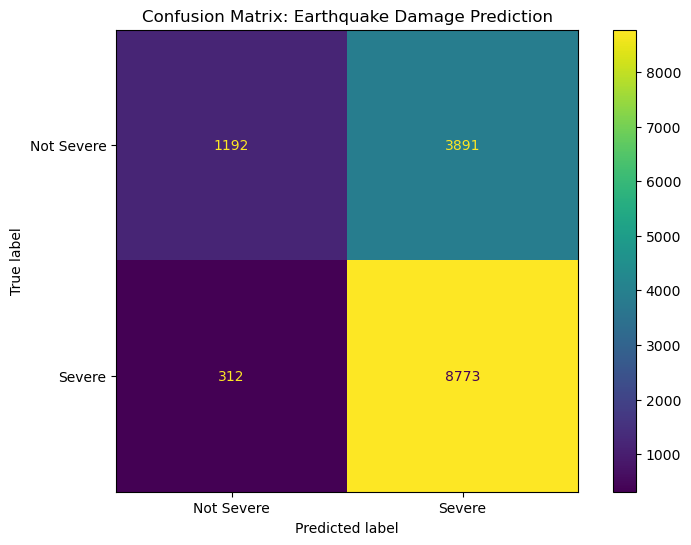

In [355]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize = (9,6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Severe","Severe"])
disp.plot(ax=ax)
ax.set_title("Confusion Matrix: Earthquake Damage Prediction")
plt.show()

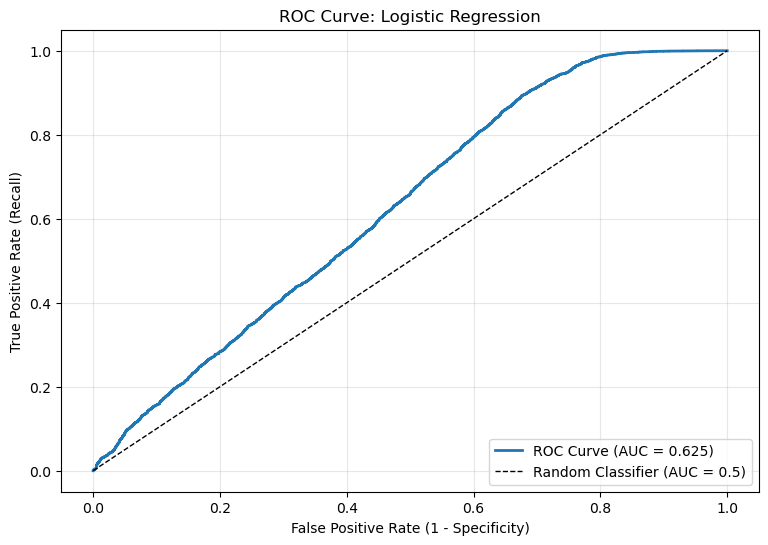

In [357]:
y_prob = model_lr.predict_proba(X_test)[:,1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)', linewidth=1)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve: Logistic Regression')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.show()

In [359]:
# Odds Ratios
feature_names = model_lr.named_steps["encoder"].get_feature_names_out()
coefficients = model_lr.named_steps["classifier"].coef_[0]

# Calculate odds ratios
odds_ratios = np.exp(coefficients)

odds_ratio_df = pd.DataFrame({
    "Feature":feature_names,
    "Coefficients": coefficients,
    "Odds Ratios": odds_ratios
}).sort_values(by="Odds Ratios")

In [376]:
odds_ratio_df = odds_ratio_df.set_index("Feature")

In [378]:
print("Top 5 features that decrease odds of severe damage:")
print(odds_ratio_df.head())
print("Top 5 features that increase odds of severe damage:")
print(odds_ratio_df.tail())

Top 5 features that decrease odds of severe damage:
                               Coefficients  Odds Ratios
Feature                                                 
foundation_type_RC                -2.487703     0.083101
ground_floor_type_RC              -1.039100     0.353773
ground_floor_type_Other           -0.360977     0.696995
foundation_type_Bamboo/Timber     -0.348960     0.705422
district_id                       -0.174510     0.839868
Top 5 features that increase odds of severe damage:
                                        Coefficients  Odds Ratios
Feature                                                          
foundation_type_Cement-Stone/Brick          0.250789     1.285039
ground_floor_type_Brick/Stone               0.458318     1.581412
ground_floor_type_Timber                    0.685711     1.985183
foundation_type_Mud mortar-Stone/Brick      1.048554     2.853523
foundation_type_Other                       1.493692     4.453507


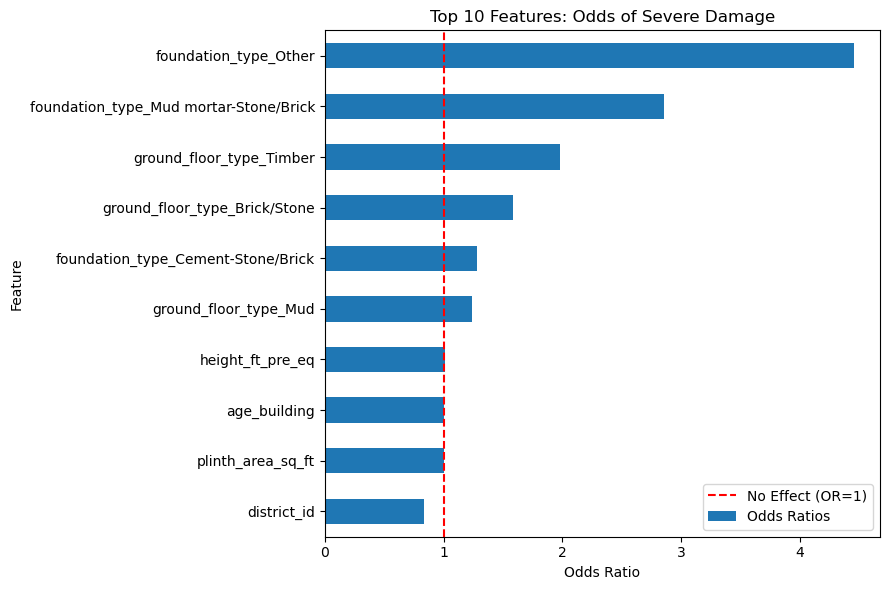

In [380]:
# Plot top 10 odds ratios
fig, ax = plt.subplots(figsize=(9, 6))
odds_ratio_df["Odds Ratios"].tail(10).plot(kind='barh', ax=ax)
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Features: Odds of Severe Damage')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect (OR=1)')
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Decision Tree Classification

In [382]:
# First split: separate test set (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size = 0.2, random_state=42)
# Second split: separate validation from training 
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,y_train_val, test_size = 0.25, random_state=42)
print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X):.1%})")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X):.1%})")
print(f"Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X):.1%})")

Training set: 42501 samples (60.0%)
Validation set: 14167 samples (20.0%)
Test set: 14168 samples (20.0%)


In [392]:
# Decision Tree
model_dt = Pipeline([
    ("encoder", ce.OrdinalEncoder()),
    ("tree", DecisionTreeClassifier(max_depth=6, random_state=42))
])
# Fit model
model_dt.fit(X_train, y_train)
# Calculate accuracies 
train_acc = accuracy_score(y_train, model_dt.predict(X_train))
val_acc = accuracy_score(y_val,model_dt.predict(X_val))
print(f"Training Accuracy: {train_acc}")
print(f"Validating Accuracy: {val_acc}")
print(f"Baseline Accuracy: {baseline_acc}")

Training Accuracy: 0.7126420554810475
Validating Accuracy: 0.7120067763111456
Baseline Accuracy: 0.6429378132279241


In [394]:
# Hyperparameter Tuning
depths = range(1,16)
train_accuracies = []
val_accuracies = []

for depth in depths:
    model_dt = Pipeline([
        ("encoder",ce.OrdinalEncoder()),
        ("tree", DecisionTreeClassifier(max_depth = depth, random_state=42))
    ])
    model_dt.fit(X_train,y_train)
    # Calculate accuracies
    train_acc = accuracy_score(y_train, model_dt.predict(X_train))
    val_acc = accuracy_score(y_val,model_dt.predict(X_val))
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

In [402]:
df_depth=pd.DataFrame({
    "Depth":depths,
    "Train Accuracy": train_accuracies,
    "Val Accuracy": val_accuracies,
})
df_depth = df_depth.set_index("Depth")
df_depth

,Train Accuracy,Val Accuracy
Depth,,
1,0.694878,0.692031
2,0.694878,0.692031
3,0.704054,0.702972
4,0.705372,0.704172
5,0.709960,0.709607
6,0.712642,0.712007
7,0.716242,0.711230
8,0.719371,0.712007
9,0.723065,0.713771


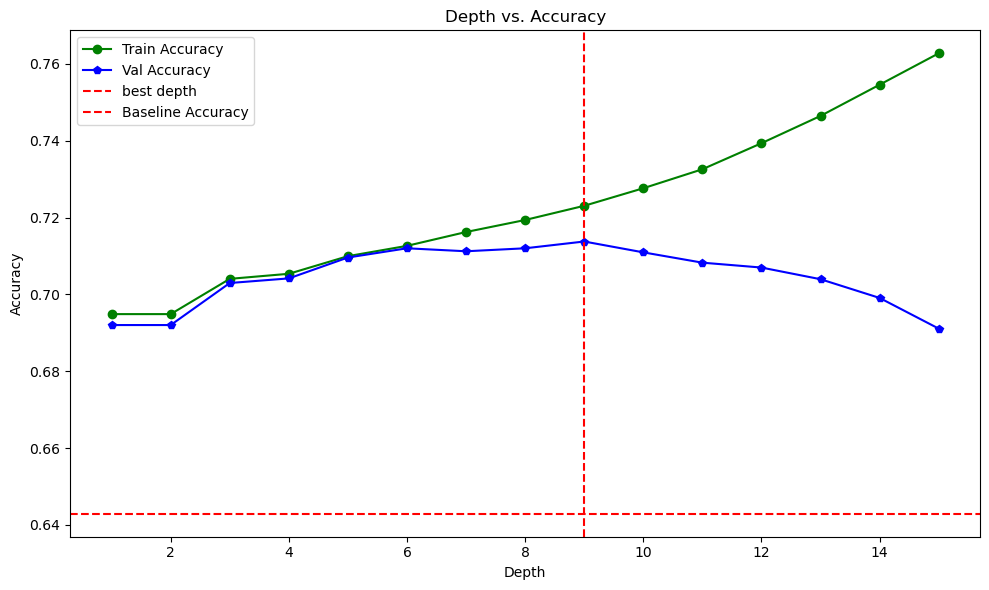

In [456]:
fig, ax = plt.subplots(figsize = (10,6))
ax.plot(df_depth.index,df_depth["Train Accuracy"], color="green", marker = "o", label="Train Accuracy")
ax.plot(df_depth.index, df_depth["Val Accuracy"], color = "blue", marker="p", label="Val Accuracy")
ax.axvline(x=df_depth["Val Accuracy"].idxmax(),linestyle="--", color = "red", label = "best depth")
ax.axhline(y=baseline_acc, color = "red", linestyle="--", label="Baseline Accuracy")
ax.set_xlabel("Depth")
ax.set_ylabel("Accuracy")
ax.set_title("Depth vs. Accuracy")
plt.tight_layout()
plt.legend()
plt.show()

In [462]:
# Train final model
final_dt = Pipeline([
    ("encoder", ce.OrdinalEncoder()),
    ("classifier", DecisionTreeClassifier(max_depth=9, random_state=42))
])
final_dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoder', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['di...id', 'ag...ng', 'pl...ft', 'he...eq', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,mapping,"[{'col': 'foundation_type', 'data_type': dtype('O'), 'mapping': Mud mortar-St...2 dtype: int64}, {'col': 'ground_floor_type', 'data_type': dtype('O'), 'mapping': Mud ...2 dtype: int64}]"
,cols,"['foundation_type', 'ground_floor_type']"
,verbose,0


In [468]:
# Evaluate on test set
test_acc = accuracy_score(y_test, final_dt.predict(X_test))
print(test_acc)

0.7081451157538114


In [494]:
importances = final_dt.named_steps["classifier"].feature_importances_
feature_names = final_dt.named_steps["encoder"].get_feature_names_out()
feature_importance = pd.DataFrame({
    "Importance": importances,
    "Feature": feature_names
})
feature_importance = feature_importance.set_index("Feature").sort_values("Importance")

<Axes: ylabel='Feature'>

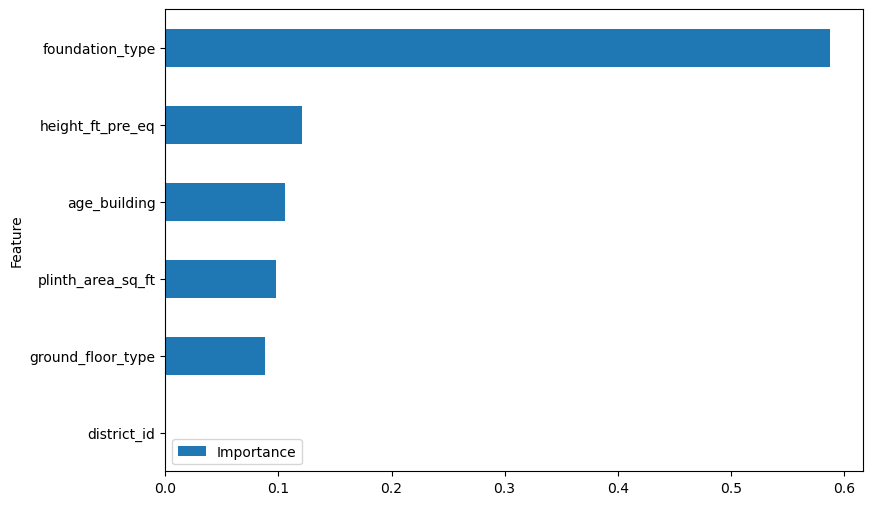

In [496]:
fig, ax = plt.subplots(figsize=(9,6))
feature_importance.head(10).plot(kind = "barh", ax=ax)

# 4. Demographics and Building Damage

### 4.1 Modeling

In [499]:
household_demographics.head()

,household_id,gender_household_head,age_household_head,caste_household,education_level_household_head,income_level_household,size_household,is_bank_account_present_in_household
0,101,Male,31.0,Rai,Illiterate,Rs. 10 thousand,3.0,0.0
1,201,Female,62.0,Rai,Illiterate,Rs. 10 thousand,6.0,0.0
2,301,Male,51.0,Gharti/Bhujel,Illiterate,Rs. 10 thousand,13.0,0.0
3,401,Male,48.0,Gharti/Bhujel,Illiterate,Rs. 10 thousand,5.0,0.0
4,501,Male,70.0,Gharti/Bhujel,Illiterate,Rs. 10 thousand,8.0,0.0


In [573]:
district_id = 4
query = f"""
    SELECT 
        h.*,
        s.*,
        i.vdcmun_id,
        d.damage_grade
    FROM household_demographics h
    JOIN id_map i ON h.household_id = i.household_id
    JOIN building_structure s ON i.building_id = s.building_id
    JOIN building_damage d ON i.building_id = d.building_id
    WHERE i.district_id = {district_id}
"""

In [575]:
df2 = duckdb.sql(query).df()

In [577]:
df2

,household_id,gender_household_head,age_household_head,caste_household,education_level_household_head,income_level_household,size_household,is_bank_account_present_in_household,building_id,count_floors_pre_eq,count_floors_post_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,height_ft_post_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,condition_post_eq,superstructure,vdcmun_id,damage_grade
0,20480101,Female,30.0,Gurung,Non-formal education,Rs. 10-20 thousand,4.0,1.0,204801,2,0,8,527,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Attached-1 side,Rectangular,Damaged-Rubble unclear,"Stone, mud mortar",30,Grade 5
1,20480201,Female,35.0,Ghale,Illiterate,Rs. 10 thousand,5.0,0.0,204802,2,0,7,670,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,Damaged-Rubble Clear-New building built,"Stone, mud mortar",30,Grade 5
2,20480301,Male,39.0,Gurung,Illiterate,Rs. 10 thousand,8.0,0.0,204803,2,0,8,756,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,Damaged-Rubble Clear-New building built,"Stone, mud mortar",30,Grade 5
3,20480401,Female,40.0,Ghale,Illiterate,Rs. 10 thousand,6.0,0.0,204804,2,0,2,480,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,Covered by landslide,"Stone, mud mortar",30,Grade 5
4,20480501,Male,56.0,Gurung,Illiterate,Rs. 10 thousand,9.0,0.0,204805,2,0,50,255,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Attached-1 side,Rectangular,Damaged-Rubble Clear-New building built,"Stone, mud mortar",30,Grade 5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75878,20292901,Female,43.0,Magar,SLC or equivalent,Rs. 30-50 thousand,3.0,1.0,202929,3,0,39,990,16,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble clear,"Stone, mud mortar",39,Grade 5
75879,20346101,Male,48.0,Gurung,Illiterate,Rs. 10 thousand,6.0,0.0,203461,2,0,20,231,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Damaged-Rubble Clear-New building built,"Stone, mud mortar",30,Grade 5
75880,20354501,Male,63.0,Gurung,Non-formal education,Rs. 10-20 thousand,5.0,0.0,203545,2,0,36,759,14,0,Steep slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble clear,"Stone, mud mortar",30,Grade 5
75881,20360901,Female,58.0,Gurung,Non-formal education,Rs. 50 thousand or more,7.0,0.0,203609,2,0,26,600,14,0,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Damaged-Rubble unclear,"Stone, mud mortar",30,Grade 5


In [579]:
df2.shape

(75883, 26)

In [581]:
cols_to_drop = [col for col in df2.columns if "post_eq" in col] + ["building_id","damage_grade","count_floors_pre_eq"]
df2 = (df2
    .assign(severe_damage = lambda x: x["damage_grade"].str.contains("Grade 4|Grade 5").astype(int))
    .set_index("household_id")
    .drop(columns = cols_to_drop)
)

In [583]:
df2["caste_household"].value_counts()

caste_household
Gurung           15119
Brahman-Hill     13043
Chhetree          8766
Magar             8180
Sarki             6052
                 ...  
Satar/Santhal        1
Kalar                1
Hyolmo               1
Byasi/Sauka          1
Dhimal               1
Name: count, Length: 63, dtype: int64

In [585]:
# Check unique values in categorical columns
cat_cols = df2.select_dtypes(include = ["object","string"]).columns
cardinality = df2[cat_cols].nunique().sort_values(ascending = False)
cardinality

caste_household                   63
education_level_household_head    19
superstructure                    11
plan_configuration                10
income_level_household             5
foundation_type                    5
ground_floor_type                  5
other_floor_type                   4
position                           4
land_surface_condition             3
roof_type                          3
gender_household_head              2
dtype: int64

In [587]:
# Get top 10
top_10_castes = (df2["caste_household"].value_counts().head(10).index)

In [589]:
df2 = (df2
     .assign(caste_household = df2["caste_household"].apply(
         lambda c: c if c in top_10_castes else "Other"
     ))
     )

In [591]:
df2["caste_household"].value_counts()

caste_household
Gurung          15119
Brahman-Hill    13043
Chhetree         8766
Other            8608
Magar            8180
Sarki            6052
Newar            5906
Kami             3565
Tamang           2396
Kumal            2271
Damai/Dholi      1977
Name: count, dtype: int64

In [605]:
# Prepare for modeling
target2 = "severe_damage"
features = [col for col in df2.columns if col not in target2]
X = df2[features]
y = df2[target]

In [607]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42)
# Baseline model
baseline_acc = y_train.value_counts(normalize = True).max()
print(baseline_acc)

0.6309755213652687


In [618]:
# Build model
model2 = Pipeline([
    ("encoder",ce.OneHotEncoder(use_cat_names = True)),
    ("classifier",LogisticRegression(max_iter=1000))
])
model2.fit(X_train, y_train)
train_acc = accuracy_score(y_train, model2.predict(X_train))
test_acc = accuracy_score(y_test, model2.predict(X_test))
print(train_acc)
print(test_acc)

0.7286594405824794
0.7239243592277789


In [642]:
feature2_names = model2.named_steps["encoder"].get_feature_names_out()
coefficients2 = model2.named_steps["classifier"].coef_[0]

odds_ratio2 = np.exp(coefficients2)
results = pd.DataFrame({
    "Feature": feature2_names,
    "Importance": coefficients2,
    "Odds Ratio": odds_ratio2
})

In [644]:
results = results.set_index("Feature").sort_values(by = "Odds Ratio", ascending = False)

In [646]:
results

,Importance,Odds Ratio
Feature,,
superstructure_Stone,1.198365,3.314694
roof_type_Bamboo/Timber-Light roof,0.954440,2.597216
"superstructure_Stone, mud mortar",0.876659,2.402858
foundation_type_Other,0.849234,2.337856
roof_type_Bamboo/Timber-Heavy roof,0.796452,2.217660
...,...,...
other_floor_type_RCC/RB/RBC,-0.254730,0.775126
"superstructure_RC, non-engineered",-0.275261,0.759374
roof_type_RCC/RB/RBC,-0.399251,0.670822


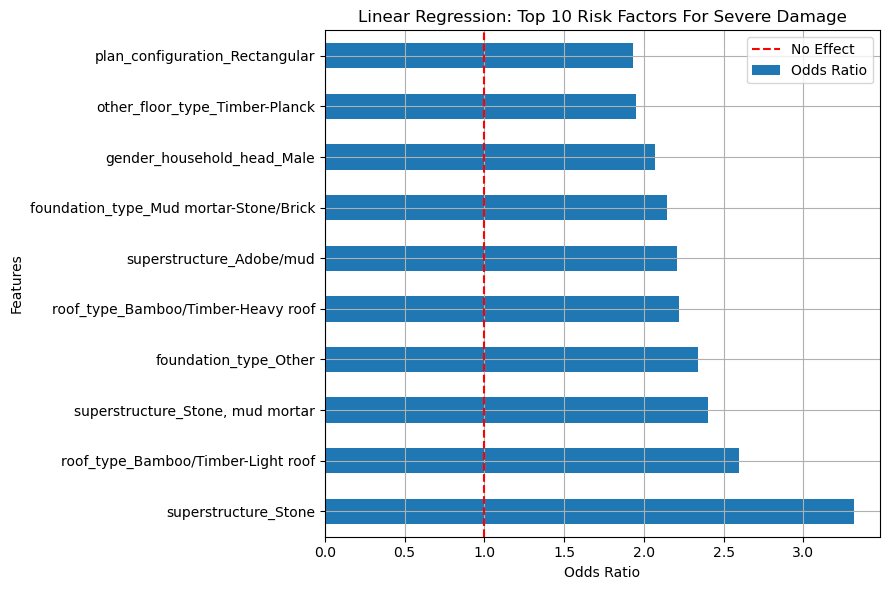

In [656]:
fig, ax = plt.subplots(figsize = (9,6))
results["Odds Ratio"].head(10).plot(kind = "barh", ax = ax)
ax.axvline(x=1, color = "red", linestyle="--", label = "No Effect")
ax.set_xlabel("Odds Ratio")
ax.set_ylabel("Features")
ax.set_title("Linear Regression: Top 10 Risk Factors For Severe Damage")
plt.tight_layout()
plt.legend()
plt.grid()
plt.show()

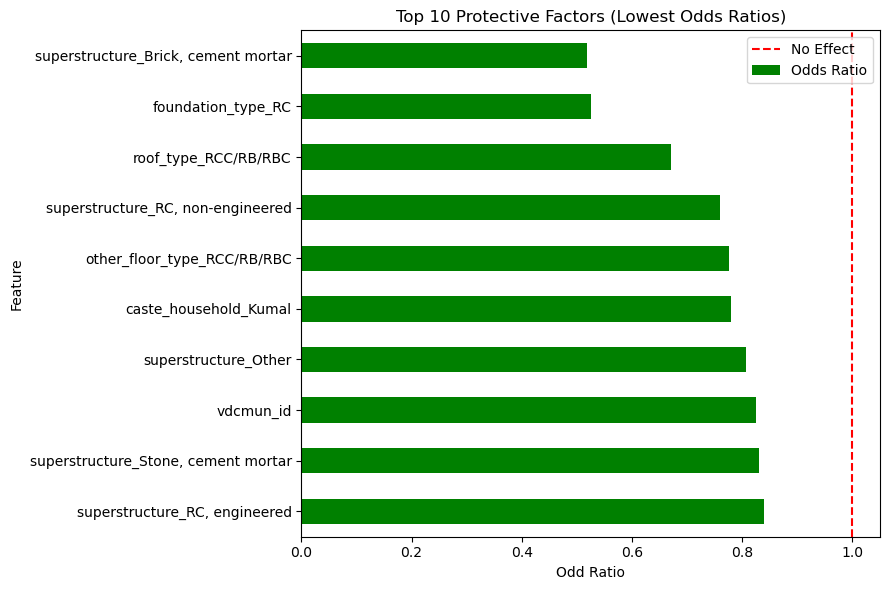

In [701]:
fig, ax = plt.subplots(figsize = (9,6))
results["Odds Ratio"].tail(10).plot(kind = "barh", ax = ax, color = "Green")
ax.axvline(x=1, color = "red", linestyle="--", label = "No Effect")
ax.set_xlabel("Odd Ratio")
ax.set_ylabel("Feature")
ax.set_title("Top 10 Protective Factors (Lowest Odds Ratios)")
plt.tight_layout()
plt.legend()
plt.show()

### 4.2 Municipal Analysis - Where Is Damage Highest?

In [671]:
damage_by_municipality = df2.groupby("vdcmun_id")["severe_damage"].agg(["mean","count"])
damage_by_municipality.columns = ["Damage Rate", "Number"]
damage_by_municipality = damage_by_municipality.sort_values("Damage Rate")

In [760]:
damage_by_municipality

,Damage Rate,Number
vdcmun_id,,
37,0.437789,13390
36,0.503972,5790
38,0.506425,11362
40,0.512444,6951
39,0.572344,7492
34,0.666979,2132
33,0.782464,6615
30,0.824201,6917
35,0.827145,3905


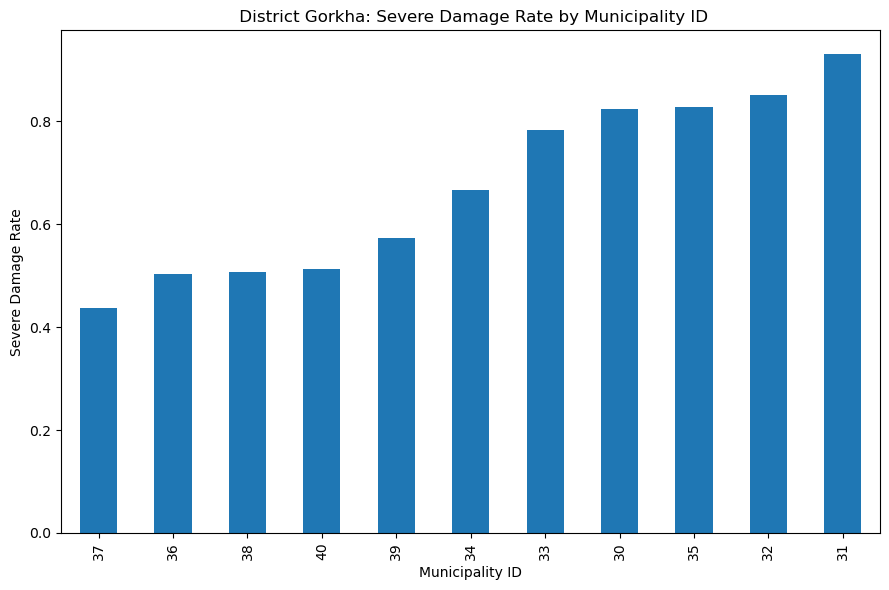

In [683]:
fig, ax = plt.subplots(figsize = (9,6))
damage_by_municipality["Damage Rate"].head(15).plot(kind = "bar", ax = ax)
ax.set_xlabel("Municipality ID")
ax.set_ylabel("Severe Damage Rate")
ax.set_title(" District Gorkha: Severe Damage Rate by Municipality ID")
plt.tight_layout()
plt.show()

In [705]:
damage_by_geo = damage_by_municipality.sort_index(axis=0)

Text(0, 0.5, 'Severe Damage Rate')

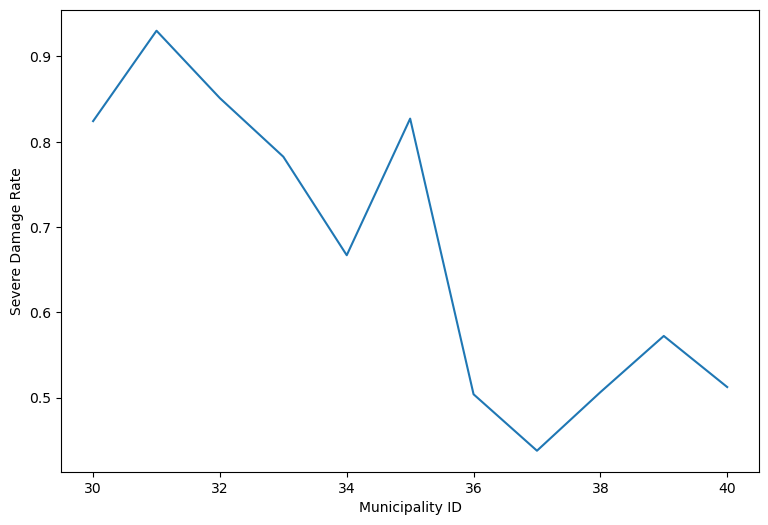

In [713]:
fig, ax = plt.subplots(figsize=(9,6))
damage_by_geo["Damage Rate"].plot(kind = "line", ax=ax)
ax.set_xlabel("Municipality ID")
ax.set_ylabel("Severe Damage Rate")

### 4.3 Demographics by Municipality - Caste Analysis

In [722]:
caste_analysis = df2.groupby("caste_household")["severe_damage"].mean().sort_values()

Text(0, 0.5, 'Caste Household')

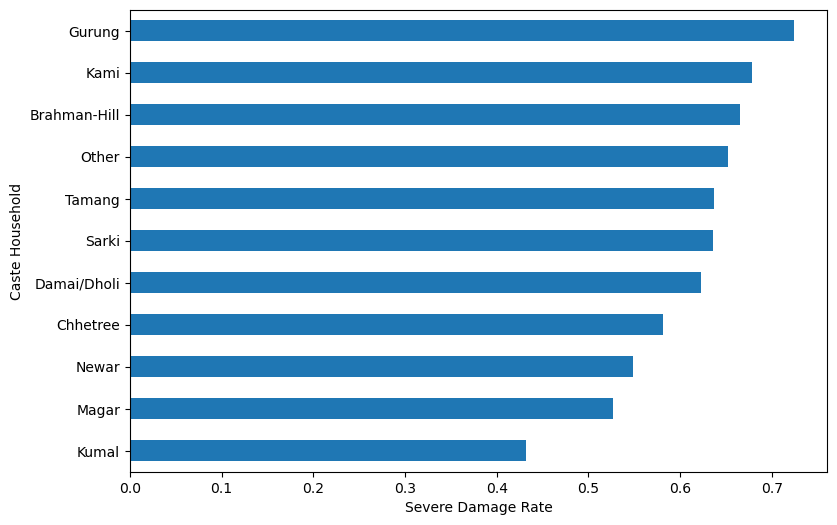

In [728]:
fig, ax = plt.subplots(figsize = (9,6))
caste_analysis.plot(kind = "barh", ax=ax)
ax.set_xlabel("Severe Damage Rate")
ax.set_ylabel("Caste Household")

In [744]:
gurung_commodity = df2[df2["caste_household"] == "Gurung"].groupby("vdcmun_id").size()

In [773]:
total = df2.groupby("vdcmun_id").size()
damage_by_municipality["gurung_pct"] = gurung_commodity/ total

In [779]:
damage_by_municipality = damage_by_municipality.sort_values(by = "gurung_pct")
damage_by_municipality

,Damage Rate,Number,gurung_pct
vdcmun_id,,,
33,0.782464,6615,0.011943
38,0.506425,11362,0.049023
37,0.437789,13390,0.050485
39,0.572344,7492,0.097971
36,0.503972,5790,0.143178
40,0.512444,6951,0.246727
31,0.930199,4169,0.326937
30,0.824201,6917,0.338152
34,0.666979,2132,0.385084


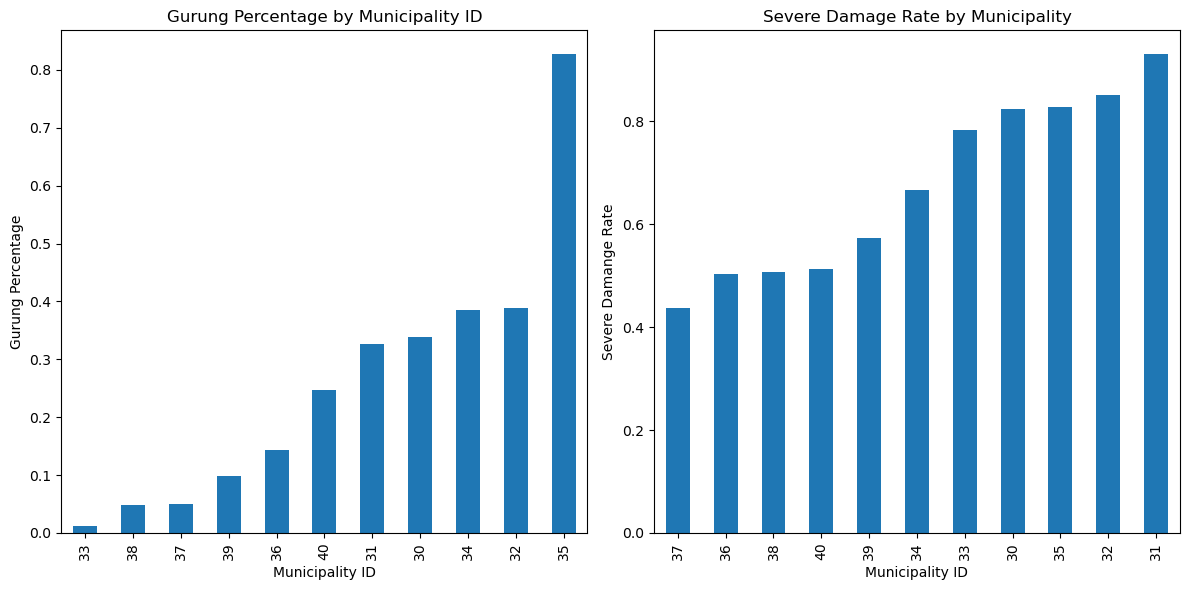

In [793]:
fig, axes = plt.subplots(1,2, figsize = (12,6))
damage_by_municipality["gurung_pct"].plot(kind = "bar", ax=axes[0])
axes[0].set_xlabel("Municipality ID")
axes[0].set_ylabel("Gurung Percentage")
axes[0].set_title("Gurung Percentage by Municipality ID")
damage_by_municipality["Damage Rate"].sort_values().plot(kind = "bar", ax=axes[1])
axes[1].set_xlabel("Municipality ID")
axes[1].set_ylabel("Severe Damange Rate")
axes[1].set_title("Severe Damage Rate by Municipality")
plt.tight_layout()